# Parcial práctico DDYA 2026-2
## Colas de prioridad y árbol de expansión mínima

En este notebook se resuelven los puntos del parcial. Primero se organiza la atención de tareas con un Max-Heap y después se conectan los dispositivos usando el algoritmo de Kruskal.

Los algoritmos principales están programados aquí. No se usa `heapq` ni una función que construya automáticamente el árbol de expansión mínima.

In [2]:
# Datos del estudiante
nombre_estudiante = "Juan Pablo Leon Davila"
codigo = "1000114216"



## 1. Cola de prioridad: descripción del problema

La empresa necesita atender tareas técnicas según su nivel de prioridad. Una tarea con prioridad más alta debe procesarse antes que las demás. Para administrar estas tareas se utiliza una **cola de prioridad Max**, implementada mediante un **Max-Heap**.

En un Max-Heap, cada nodo padre tiene una prioridad mayor o igual que la de sus hijos. Por eso, la tarea de mayor prioridad siempre queda en la raíz (posición 0 del arreglo).

## 2. Requerimientos

### Requerimientos funcionales
1. Almacenar las tareas con su código, descripción y prioridad.
2. Construir un Max-Heap a partir del arreglo inicial.
3. Mostrar el arreglo inicial, el Max-Heap y su representación como árbol.
4. Extraer y procesar las dos tareas con mayor prioridad.
5. Insertar la tarea T07 con prioridad 12, conservando la propiedad del Max-Heap.
6. Calcular la distancia euclidiana entre cada pareja de dispositivos.
7. Ordenar las aristas por peso y aplicar Kruskal evitando ciclos.
8. Mostrar las cinco conexiones del MST y su longitud total en una gráfica.

### Requerimientos no funcionales
1. El código debe ser legible, modular y ejecutable en un único Notebook.
2. Los algoritmos de heap y Kruskal deben estar implementados manualmente.
3. Las distancias y los resultados deben mostrarse con precisión de dos decimales.
4. Las gráficas deben incluir etiquetas para identificar los elementos.

## 3. Historias de usuario

**Historia 1.** Como encargado técnico, quiero registrar tareas con una prioridad para que las más urgentes sean atendidas primero.  
**Criterios de aceptación:** cada tarea conserva su código, descripción y prioridad; el Max-Heap deja la prioridad mayor en la raíz.

**Historia 2.** Como encargado técnico, quiero extraer la tarea de mayor prioridad para conocer cuál debe procesarse.  
**Criterios de aceptación:** EXTRACT-MAX devuelve la tarea con mayor prioridad y reorganiza correctamente el heap.

**Historia 3.** Como encargado técnico, quiero agregar una tarea urgente para que quede ubicada según su prioridad.  
**Criterios de aceptación:** al insertar T07 con prioridad 12, la propiedad del Max-Heap se mantiene.

**Historia 4.** Como administrador de infraestructura, quiero conocer las distancias entre dispositivos para estimar el cable necesario.  
**Criterios de aceptación:** se calcula una distancia para cada pareja de dispositivos y se representa cada pareja como una arista.

**Historia 5.** Como administrador de infraestructura, quiero conectar todos los dispositivos con el menor cable posible.  
**Criterios de aceptación:** Kruskal selecciona exactamente cinco aristas, no forma ciclos y muestra el peso total.

## 4. Diagramas de flujo

### Proceso general

1. Leer las tareas y construir el Max-Heap.
2. Extraer dos veces la raíz para procesar las dos tareas prioritarias.
3. Insertar T07 y reorganizar el heap.
4. Cargar las coordenadas de los dispositivos y calcular todas las distancias.
5. Ordenar las aristas de menor a mayor peso.
6. Recorrer las aristas: aceptar una conexión solo si une componentes diferentes.
7. Detenerse al seleccionar cinco conexiones y graficar el MST.

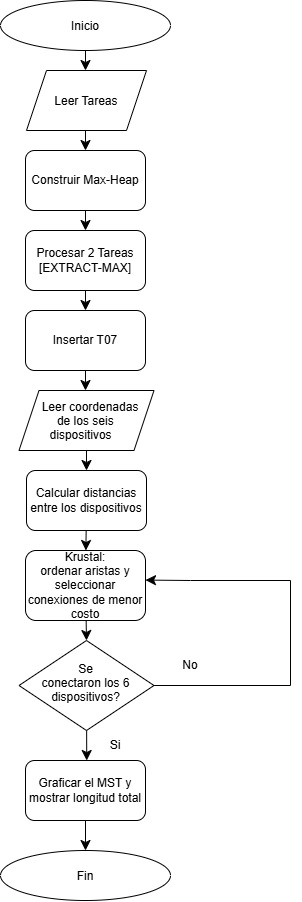

## 5. Análisis de complejidad

Para el heap, `n` representa la cantidad de tareas. Para el grafo, `V` es la cantidad de dispositivos y `E` la cantidad de conexiones posibles.

| Operación | Complejidad | Razón |
|---|---:|---|
| `MAX-HEAPIFY` | O(log n) | Puede bajar por los niveles del árbol hasta una hoja. |
| `BUILD-MAX-HEAP` | O(n) | El costo total de reorganizar todos los nodos es lineal. |
| `EXTRACT-MAX` | O(log n) | Se reemplaza la raíz y se reorganiza el heap. |
| Insertar en el heap | O(log n) | El nuevo elemento puede subir desde una hoja hasta la raíz. |
| Calcular todas las distancias | O(V²) | Se recorre cada pareja de dispositivos una sola vez. |
| Ordenar aristas con Insertion Sort | O(E²) | En el peor caso, cada arista puede compararse y desplazarse frente a las anteriores. |
| Kruskal con este ordenamiento | O(E²) | El ordenamiento manual domina el costo; las operaciones Union-Find son casi constantes amortizadas. |

La altura de un heap es proporcional a `log₂(n)`. Por eso las operaciones que recorren un camino del árbol tienen costo logarítmico. En cambio, construir el heap completo cuesta O(n), porque no todos los nodos recorren toda la altura.

En este ejercicio hay 6 dispositivos. Por tanto, el número de parejas es 6·5/2 = **15 aristas**. Un árbol de expansión mínima que conecta 6 vértices debe tener exactamente 6−1 = **5 aristas**.

**Nota sobre Kruskal:** en este notebook las aristas se ordenan con Insertion Sort para mostrar el procedimiento manual. Por eso el costo total de esta implementación es O(E²), aunque otras implementaciones de Kruskal suelen usar un ordenamiento O(E log E).

### Gráfica de crecimiento de complejidad

La siguiente gráfica compara el crecimiento de O(n), O(log n), O(n²) y O(n log n). Es una representación ilustrativa de las funciones de crecimiento, no una medición de tiempo.
## **Mejor Caso**
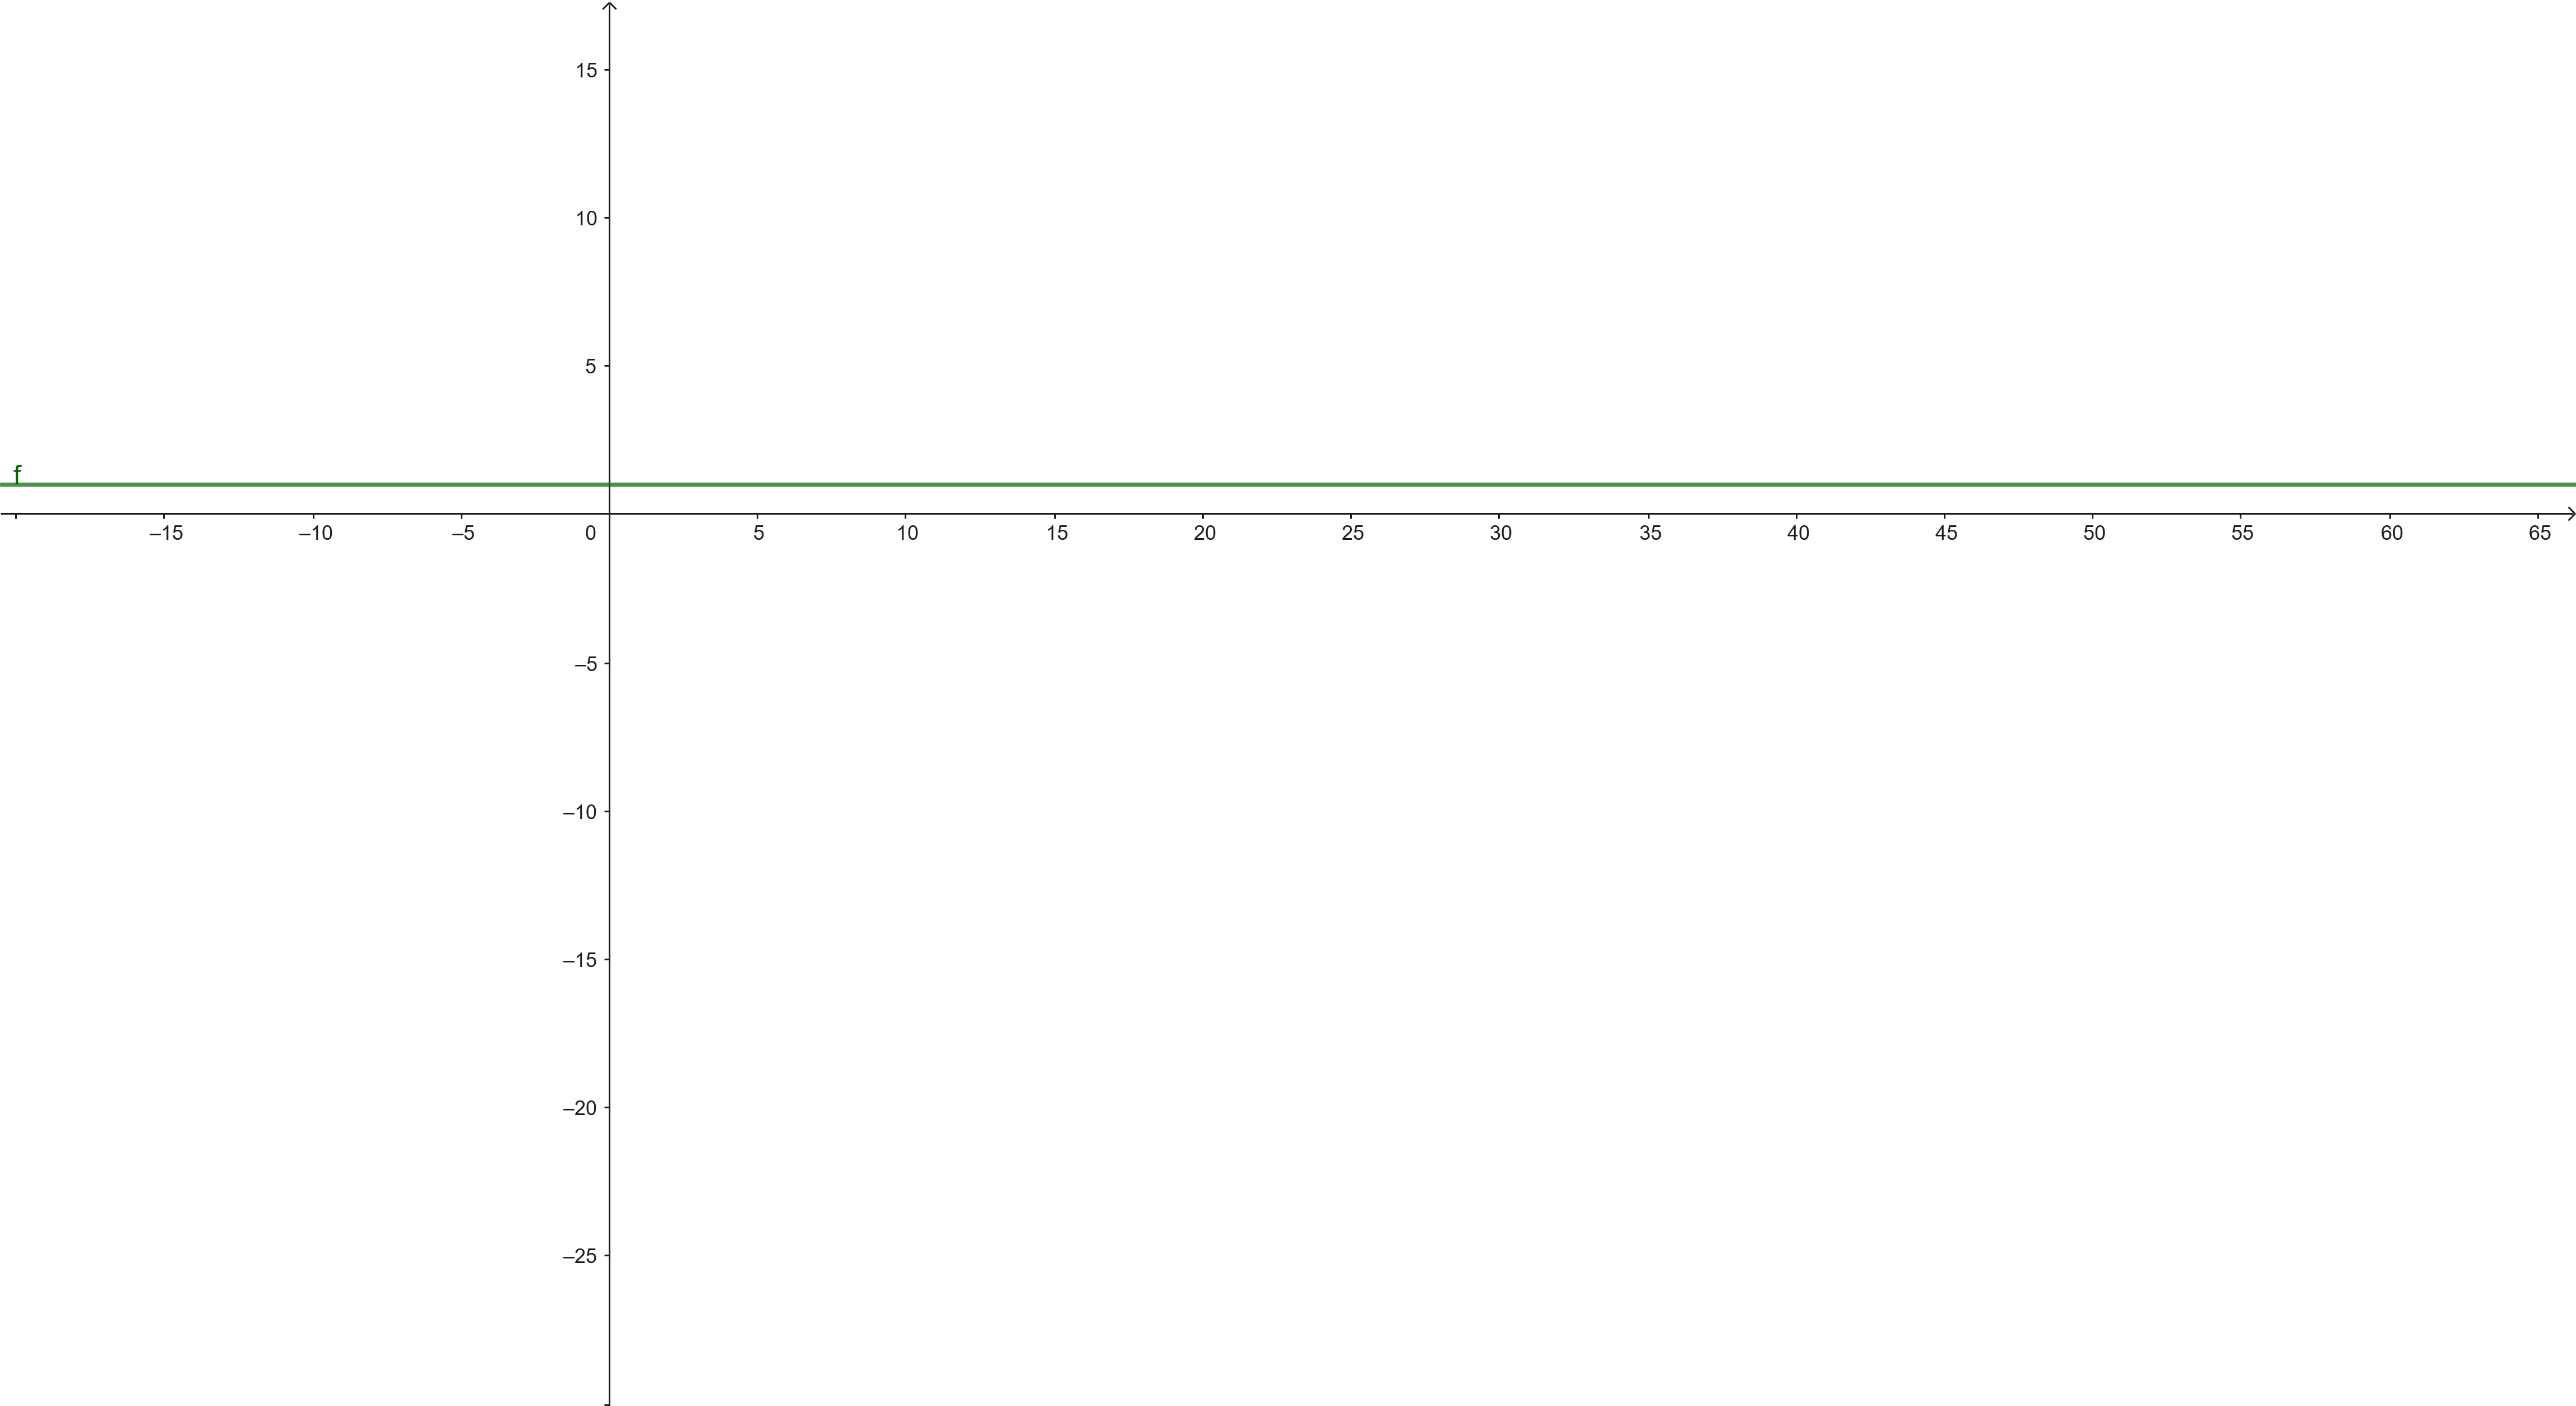

## ** Peor Caso** 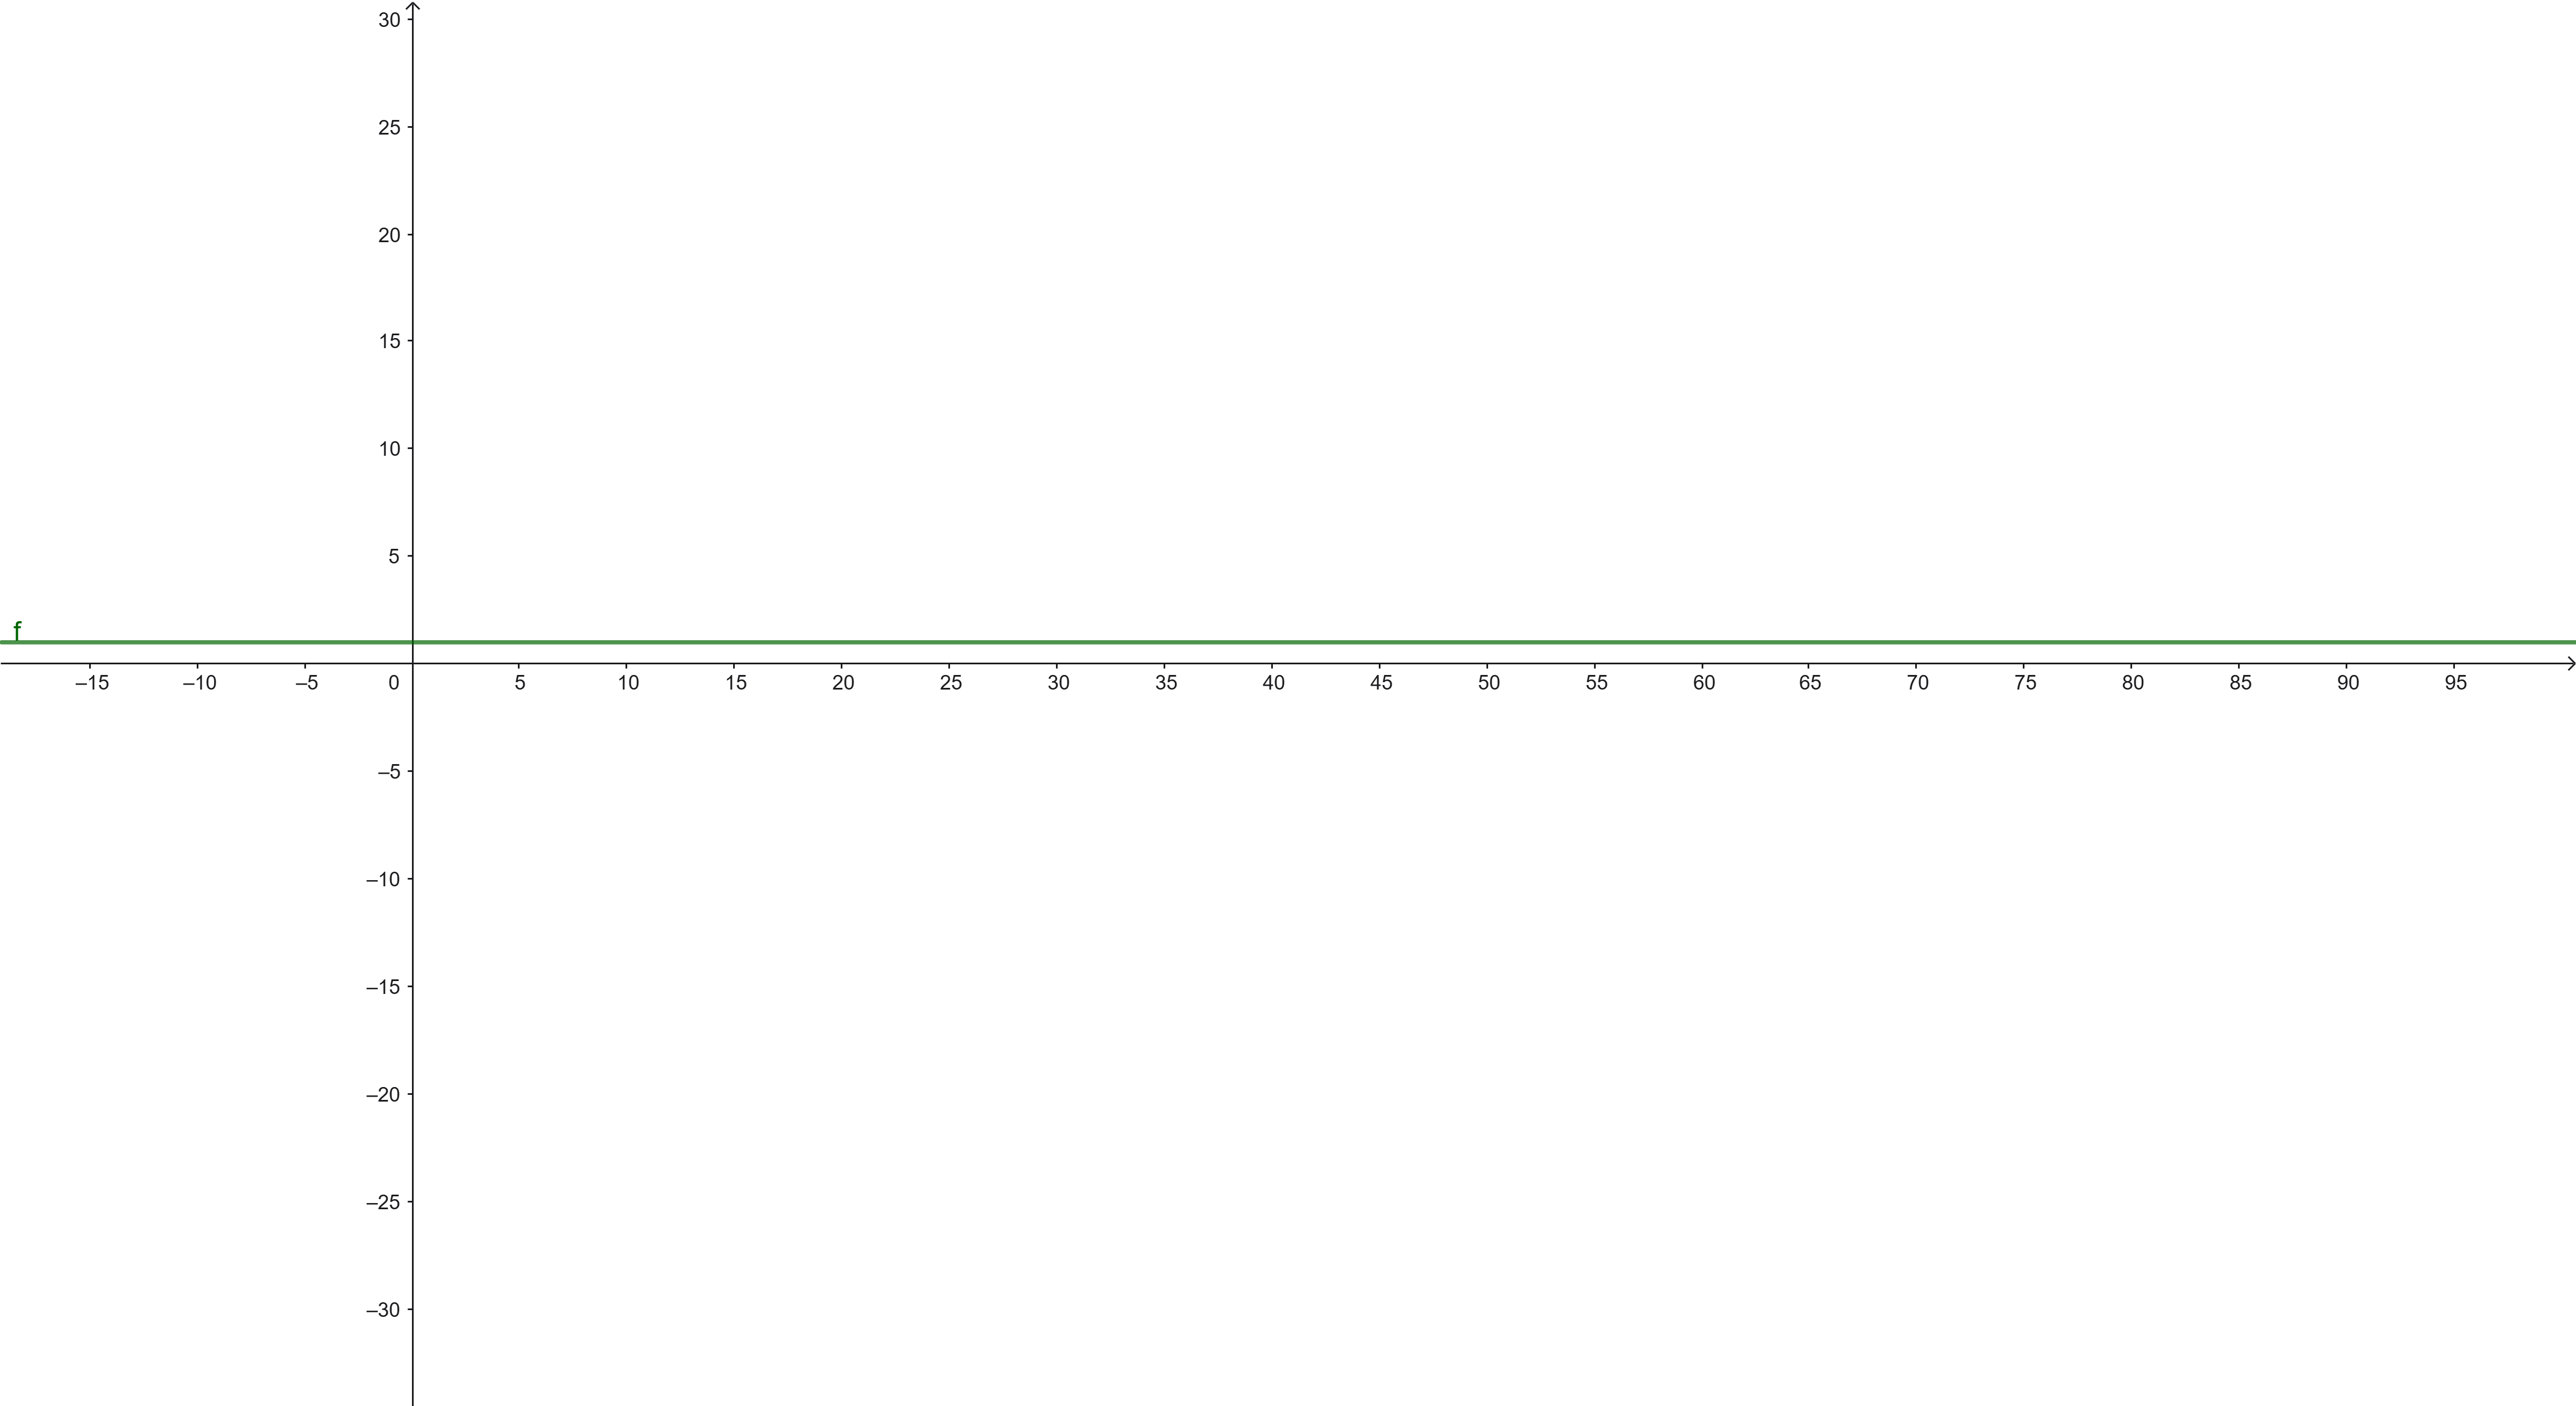

## 6. Código funcional

### Punto 1. Construcción del Max-Heap

Cada tarea se representa mediante un diccionario. Para facilitar la comparación, se utiliza el campo `prioridad`. El arreglo se indexa desde cero: el hijo izquierdo de `i` es `2*i+1` y el derecho es `2*i+2`.

In [ ]:
# Tareas iniciales del enunciado
tareas = [
    {"codigo": "T01", "tarea": "Configurar servidor", "prioridad": 6},
    {"codigo": "T02", "tarea": "Reparar sensor", "prioridad": 10},
    {"codigo": "T03", "tarea": "Actualizar software", "prioridad": 4},
    {"codigo": "T04", "tarea": "Revisar cámara", "prioridad": 8},
    {"codigo": "T05", "tarea": "Generar respaldo", "prioridad": 3},
    {"codigo": "T06", "tarea": "Configurar alarma", "prioridad": 7}
]

def mostrar_heap(heap):
    return [(t["codigo"], t["prioridad"]) for t in heap]

def max_heapify(heap, i, heap_size=None):
    if heap_size is None:
        heap_size = len(heap)

    mayor = i
    izquierdo = 2 * i + 1
    derecho = 2 * i + 2

    if izquierdo < heap_size and heap[izquierdo]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izquierdo

    if derecho < heap_size and heap[derecho]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = derecho

    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, mayor, heap_size)

def build_max_heap(heap):
    n = len(heap)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, i)
    return heap

arreglo_inicial = tareas.copy()
print("Arreglo inicial:")
print(mostrar_heap(arreglo_inicial))

heap = build_max_heap(tareas.copy())
print("\nMax-Heap resultante:")
print(mostrar_heap(heap))

Arreglo inicial:
[('T01', 6), ('T02', 10), ('T03', 4), ('T04', 8), ('T05', 3), ('T06', 7)]

Max-Heap resultante:
[('T02', 10), ('T04', 8), ('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]


### Representación del Max-Heap como árbol

El arreglo representa el árbol por niveles. La raíz contiene la tarea con mayor prioridad y cada nodo padre tiene prioridad mayor o igual que sus hijos.

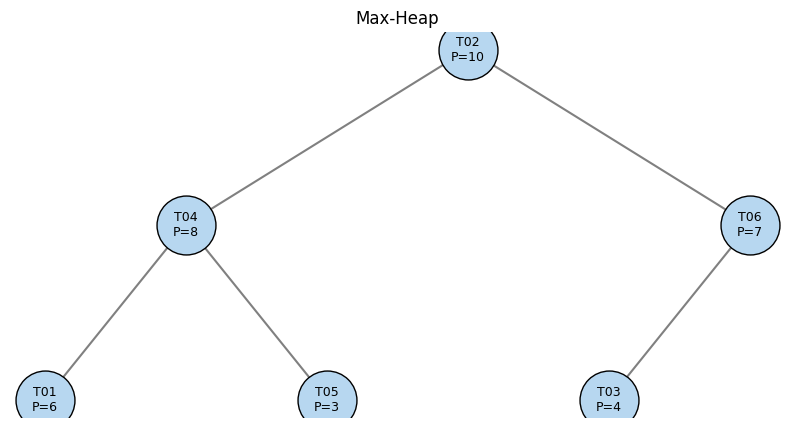

In [ ]:
def graficar_heap(heap, titulo="Max-Heap"):
    if not heap:
        print("El heap está vacío.")
        return

    posiciones = {}
    niveles = math.floor(math.log2(len(heap))) + 1

    for i, tarea in enumerate(heap):
        nivel = math.floor(math.log2(i + 1))
        posicion_nivel = i - (2 ** nivel - 1)
        cantidad_nivel = 2 ** nivel
        x = (posicion_nivel + 0.5) / cantidad_nivel
        y = niveles - nivel
        posiciones[i] = (x, y)

    plt.figure(figsize=(10, 5))
    ax = plt.gca()
    for i in range(len(heap)):
        for hijo in (2*i + 1, 2*i + 2):
            if hijo < len(heap):
                x1, y1 = posiciones[i]
                x2, y2 = posiciones[hijo]
                ax.plot([x1, x2], [y1, y2], color="gray", zorder=1)

    for i, tarea in enumerate(heap):
        x, y = posiciones[i]
        ax.scatter(x, y, s=1800, color="#b7d7f0", edgecolor="black", zorder=2)
        ax.text(x, y, f'{tarea["codigo"]}\nP={tarea["prioridad"]}',
                ha="center", va="center", fontsize=9, zorder=3)

    ax.set_title(titulo)
    ax.axis("off")
    plt.show()

graficar_heap(heap)

### Punto 2. Extracción e inserción

`EXTRACT-MAX` toma la raíz, que es la tarea de mayor prioridad, la reemplaza por el último elemento y vuelve a organizar el heap. Para insertar una tarea se agrega al final y se compara con su padre hasta que quede en la posición correcta.

Tarea procesada 1: T02 - Reparar sensor (prioridad 10)
Heap después de extraer: [('T04', 8), ('T01', 6), ('T06', 7), ('T03', 4), ('T05', 3)]
Tarea procesada 2: T04 - Revisar cámara (prioridad 8)
Heap después de extraer: [('T06', 7), ('T01', 6), ('T05', 3), ('T03', 4)]

Heap después de insertar T07:
[('T07', 12), ('T06', 7), ('T05', 3), ('T03', 4), ('T01', 6)]


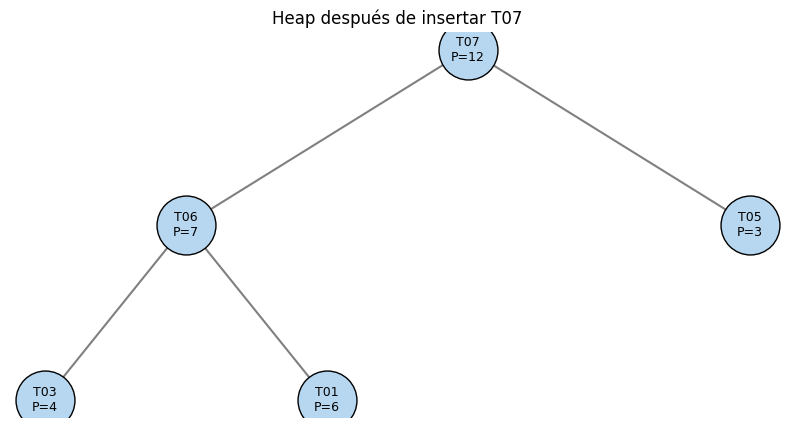

In [ ]:
def extract_max(heap):
    if len(heap) == 0:
        raise IndexError("El heap está vacío.")

    mayor = heap[0]
    ultimo = heap.pop()

    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, 0)

    return mayor


def insert_max_heap(heap, nueva_tarea):
    heap.append(nueva_tarea)
    i = len(heap) - 1

    while i > 0:
        padre = (i - 1) // 2

        if heap[padre]["prioridad"] >= heap[i]["prioridad"]:
            break

        heap[padre], heap[i] = heap[i], heap[padre]
        i = padre


# Se procesan las dos tareas que tienen mayor prioridad.
procesadas = []

for numero in range(1, 3):
    tarea = extract_max(heap)
    procesadas.append(tarea)
    print(f"Tarea procesada {numero}: {tarea['codigo']} - {tarea['tarea']} "
          f"(prioridad {tarea['prioridad']})")
    print("Heap después de extraer:", mostrar_heap(heap))

# Se agrega la nueva tarea indicada en el enunciado.
nueva_tarea = {
    "codigo": "T07",
    "tarea": "Falla en sistema contra incendios",
    "prioridad": 12
}

insert_max_heap(heap, nueva_tarea)

print("\nHeap después de insertar T07:")
print(mostrar_heap(heap))
graficar_heap(heap, "Heap después de insertar T07")

## Punto 3. Dispositivos y cálculo de distancias

Se utilizan las coordenadas entregadas en el enunciado. Para cada pareja se calcula la distancia euclidiana:

`distancia = sqrt((x2 - x1)^2 + (y2 - y1)^2)`

Con seis dispositivos se obtienen 15 parejas diferentes. Cada pareja constituye una arista y su distancia es el peso.

Cantidad de aristas: 15

Distancias entre todas las parejas:
A - B: 5.10
A - C: 5.39
A - D: 10.00
A - E: 11.05
A - F: 13.93
B - C: 5.00
B - D: 5.83
B - E: 6.00
B - F: 8.94
C - D: 6.08
C - E: 9.85
C - F: 11.00
D - E: 5.83
D - F: 5.10
E - F: 4.47


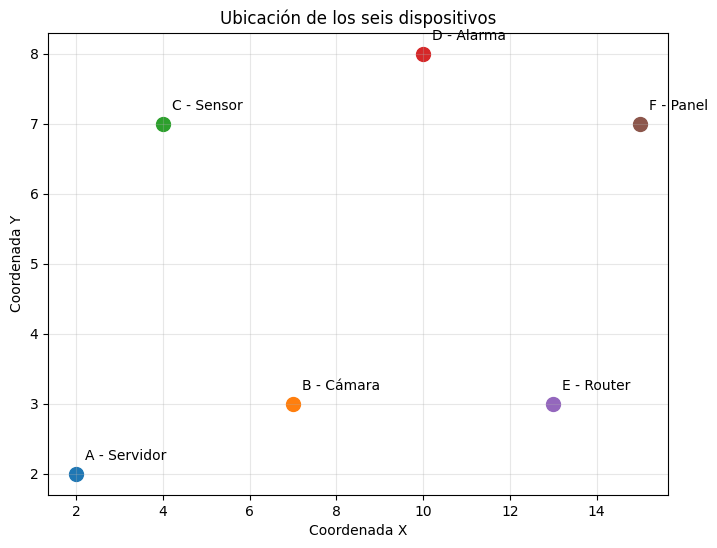

In [ ]:
dispositivos = {
    "A": {"nombre": "Servidor", "x": 2, "y": 2},
    "B": {"nombre": "Cámara", "x": 7, "y": 3},
    "C": {"nombre": "Sensor", "x": 4, "y": 7},
    "D": {"nombre": "Alarma", "x": 10, "y": 8},
    "E": {"nombre": "Router", "x": 13, "y": 3},
    "F": {"nombre": "Panel", "x": 15, "y": 7}
}

def distancia(p1, p2):
    dx = p2["x"] - p1["x"]
    dy = p2["y"] - p1["y"]
    return math.sqrt(dx**2 + dy**2)

aristas = []
ids = list(dispositivos.keys())

for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        origen = ids[i]
        destino = ids[j]
        peso = distancia(dispositivos[origen], dispositivos[destino])
        aristas.append((origen, destino, peso))

print("Cantidad de aristas:", len(aristas))
print("\nDistancias entre todas las parejas:")
for origen, destino, peso in aristas:
    print(f"{origen} - {destino}: {peso:.2f}")

# Gráfica de ubicación de los dispositivos
plt.figure(figsize=(8, 6))
for identificador, datos in dispositivos.items():
    plt.scatter(datos["x"], datos["y"], s=100)
    plt.text(datos["x"] + 0.2, datos["y"] + 0.2,
             f'{identificador} - {datos["nombre"]}')
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.title("Ubicación de los seis dispositivos")
plt.grid(True, alpha=0.3)
plt.show()

## Punto 4. Árbol de Expansión Mínima: algoritmo de Kruskal

Kruskal selecciona las aristas de menor peso, siempre que no formen un ciclo. Para detectar ciclos se implementa una estructura de conjuntos disjuntos (*Union-Find*) con las operaciones `find` y `union`.

El ordenamiento de aristas también se realiza manualmente mediante **Insertion Sort**, para no depender de una función que calcule el MST.

In [ ]:
def ordenar_aristas(aristas):
    # Insertion Sort ascendente según el peso
    ordenadas = aristas.copy()

    for i in range(1, len(ordenadas)):
        actual = ordenadas[i]
        j = i - 1

        while j >= 0 and ordenadas[j][2] > actual[2]:
            ordenadas[j + 1] = ordenadas[j]
            j -= 1

        ordenadas[j + 1] = actual

    return ordenadas

def find(padre, elemento):
    if padre[elemento] != elemento:
        padre[elemento] = find(padre, padre[elemento])
    return padre[elemento]

def union(padre, rango, a, b):
    raiz_a = find(padre, a)
    raiz_b = find(padre, b)

    if raiz_a == raiz_b:
        return False

    if rango[raiz_a] < rango[raiz_b]:
        padre[raiz_a] = raiz_b
    elif rango[raiz_a] > rango[raiz_b]:
        padre[raiz_b] = raiz_a
    else:
        padre[raiz_b] = raiz_a
        rango[raiz_a] += 1

    return True

def kruskal(vertices, aristas):
    aristas_ordenadas = ordenar_aristas(aristas)
    padre = {v: v for v in vertices}
    rango = {v: 0 for v in vertices}
    mst = []
    costo_total = 0

    print("Aristas ordenadas de menor a mayor:")
    for a, b, peso in aristas_ordenadas:
        print(f"{a} - {b}: {peso:.2f}")

    print("\nSelección de conexiones:")
    for a, b, peso in aristas_ordenadas:
        if union(padre, rango, a, b):
            mst.append((a, b, peso))
            costo_total += peso
            print(f"ACEPTADA: {a} - {b} ({peso:.2f})")
        else:
            print(f"RECHAZADA (formaría ciclo): {a} - {b} ({peso:.2f})")

        if len(mst) == len(vertices) - 1:
            break

    return mst, costo_total

mst, costo_total = kruskal(ids, aristas)

print("\nConexiones seleccionadas para el MST:")
for a, b, peso in mst:
    print(f"{a} - {b}: {peso:.2f}")

print(f"\nLongitud total de cable: {costo_total:.2f}")
print("Número de conexiones:", len(mst))

Aristas ordenadas de menor a mayor:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
A - C: 5.39
B - D: 5.83
D - E: 5.83
B - E: 6.00
C - D: 6.08
B - F: 8.94
C - E: 9.85
A - D: 10.00
C - F: 11.00
A - E: 11.05
A - F: 13.93

Selección de conexiones:
ACEPTADA: E - F (4.47)
ACEPTADA: B - C (5.00)
ACEPTADA: A - B (5.10)
ACEPTADA: D - F (5.10)
RECHAZADA (formaría ciclo): A - C (5.39)
ACEPTADA: B - D (5.83)

Conexiones seleccionadas para el MST:
E - F: 4.47
B - C: 5.00
A - B: 5.10
D - F: 5.10
B - D: 5.83

Longitud total de cable: 25.50
Número de conexiones: 5


## Punto 5. Visualización final del MST

La gráfica muestra los seis dispositivos y únicamente las conexiones seleccionadas por Kruskal. Cada conexión está etiquetada con su peso y se presenta la longitud total del cable utilizado.

Las conexiones que debe mostrar la ejecución son: E-F, B-C, A-B, D-F y B-D. La suma de sus distancias es aproximadamente **25.50 unidades**.

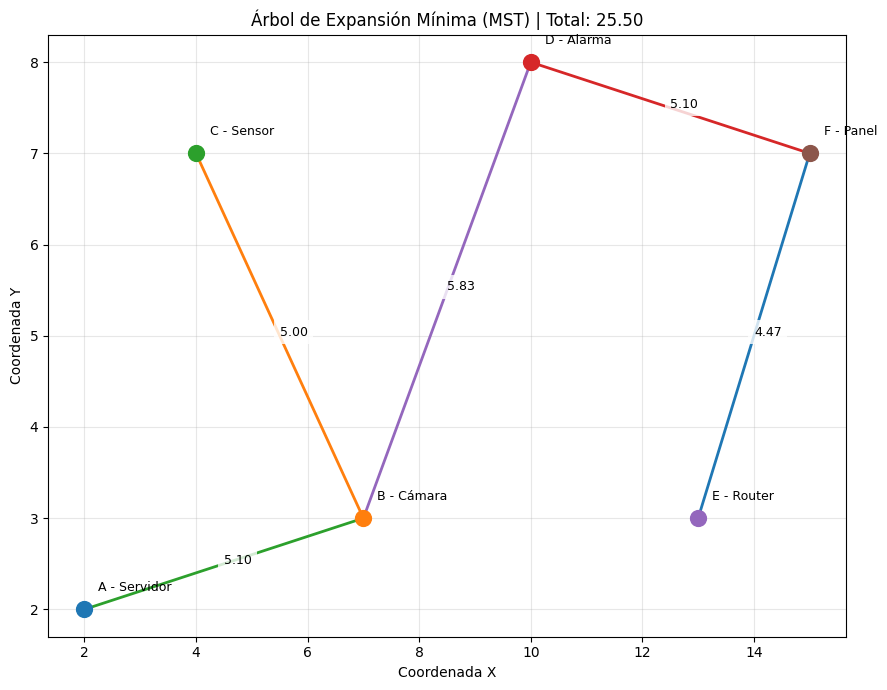

In [ ]:
plt.figure(figsize=(9, 7))

# Dibujar los dispositivos
for identificador, datos in dispositivos.items():
    plt.scatter(datos["x"], datos["y"], s=130, zorder=3)
    plt.text(datos["x"] + 0.25, datos["y"] + 0.2,
             f'{identificador} - {datos["nombre"]}', fontsize=9)

# Dibujar únicamente las aristas del MST
for a, b, peso in mst:
    x1, y1 = dispositivos[a]["x"], dispositivos[a]["y"]
    x2, y2 = dispositivos[b]["x"], dispositivos[b]["y"]
    plt.plot([x1, x2], [y1, y2], linewidth=2, zorder=2)
    xm, ym = (x1 + x2) / 2, (y1 + y2) / 2
    plt.text(xm, ym, f"{peso:.2f}", fontsize=9,
             bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))

plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.title(f"Árbol de Expansión Mínima (MST) | Total: {costo_total:.2f}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Tests aplicados

Se hacen comprobaciones para revisar que las operaciones principales hayan quedado bien: las dos tareas extraídas deben ser las de prioridad 10 y 8, T07 debe quedar en la raíz y el MST debe tener cinco conexiones sin ciclos.

In [ ]:
def es_max_heap(heap):
    for i in range(len(heap)):
        izquierdo = 2 * i + 1
        derecho = 2 * i + 2

        if izquierdo < len(heap):
            if heap[i]["prioridad"] < heap[izquierdo]["prioridad"]:
                return False

        if derecho < len(heap):
            if heap[i]["prioridad"] < heap[derecho]["prioridad"]:
                return False

    return True


# Revisar las extracciones y la inserción.
assert [t["prioridad"] for t in procesadas] == [10, 8]
assert [t["codigo"] for t in procesadas] == ["T02", "T04"]
assert es_max_heap(heap)
assert heap[0]["codigo"] == "T07"
assert heap[0]["prioridad"] == 12

# Un MST de seis vértices debe tener cinco aristas.
assert len(mst) == len(dispositivos) - 1

# Comprobar que las cinco aristas no formen ciclos.
padre_test = {v: v for v in ids}
rango_test = {v: 0 for v in ids}

for a, b, peso in mst:
    assert union(padre_test, rango_test, a, b), "Se encontró un ciclo."

# Comprobar que todos los dispositivos quedaron conectados.
raices = set(find(padre_test, v) for v in ids)
assert len(raices) == 1

print("Todas las pruebas pasaron.")
print("Extracciones:", [t["codigo"] for t in procesadas])
print("Raíz del heap:", heap[0]["codigo"], "con prioridad", heap[0]["prioridad"])
print("Conexiones del MST:", len(mst))
print(f"Longitud total: {costo_total:.2f}")

Todas las pruebas pasaron.
Extracciones: ['T02', 'T04']
Raíz del heap: T07 con prioridad 12
Conexiones del MST: 5
Longitud total: 25.50


## Conclusión

Se implementó una cola de prioridad Max mediante un Max-Heap, incluyendo su construcción, extracción e inserción. Luego se calcularon las distancias entre todos los pares de dispositivos y se aplicó Kruskal con una estructura Union-Find para obtener un árbol de expansión mínima. El resultado conecta los seis dispositivos con cinco aristas, sin ciclos y con el menor peso total posible.